# Debug / visualise the COSEM3D crops

Audits every volume in `data/COSEM3D/` (OpenOrganelle / COSEM FIB-SEM: HeLa, Jurkat, macrophage) against the
**online reference** and keeps **only meaningful regions** (cell ultrastructure; not embedding resin, flat or
saturated areas). Same conventions as `data_SNEMI3D.ipynb`: every check prints `PASS`, `FAIL`, `WARN` or `INFO` and the
last cell lists everything that is not `PASS`.

Online references used (all queried live when `ONLINE = True`, with the values embedded as a fallback):

| what | where |
| --- | --- |
| Paper | Heinrich et al. 2021, *Whole-cell organelle segmentation in volume electron microscopy*, Nature 599; Xu et al. 2021 (FIB-SEM, enhanced) |
| Portal | [OpenOrganelle](https://openorganelle.janelia.org) (`jrc_hela-3`, `jrc_jurkat-1`, `jrc_macrophage-2`), [CellMap Segmentation Challenge](https://cellmapchallenge.janelia.org/page/about) |
| Figshare records (EM voxel size, sample, DOI) | [jrc_hela-3](https://doi.org/10.25378/janelia.13117586), [jrc_jurkat-1](https://janelia.figshare.com/articles/dataset/13117697), [jrc_macrophage-2](https://janelia.figshare.com/articles/dataset/13117745) |
| Raw EM volume geometry (used here) | `s3://janelia-cosem-datasets/<id>/neuroglancer/em/fibsem-uint8.precomputed/info` (`scales[0]` = full resolution) |
| Local tooling that produced the files | `scripts/collect_meaningful_crops.py` of the source data project (gates), `resample_cosem_isotropic.py` (3.24/3.36/3.44 nm to 4 nm) |

Conventions: arrays are `(z, y, x)`; the file name `x<X>_y<Y>_z<Z>` is the tile origin **in voxels of the original
(anisotropic) `s0` grid**, so `z` is in 3.24 / 3.36 / 3.44 nm units, not 4 nm. FIB-SEM mills along `z`, so `(y, x)` is the imaging plane.


In [1]:
import os
for _v in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):   # 256-core box: keep BLAS threads sane
    os.environ.setdefault(_v, "32")
import json, re, time, glob
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ---- parameters: change and re-run -----------------------------------------------------------
ONLINE = True                 # query OpenOrganelle S3 (info files, coarse whole-volume maps); False -> embedded values
REFRESH = False               # True: ignore the caches in CACHE (patch scan, coarse maps)
MIP = 4                       # coarse level for the whole-volume map (64 nm in xy)
SCAN_P = (48, 128, 128)       # probe patch (z, y, x) in voxels: the SSL training patch scale
SCAN_STRIDE = (200, 128, 256)  # patch grid stride (z, y, x); last patch is shifted to touch the volume end
CONTENT_STD, MIN_CONTENT, MIN_AC = 0.05, 0.8, 0.5     # gates of LazyVolDataset / collect_meaningful_crops.py
MIN_NZ = 0.5                  # non-zero voxel fraction gate
BOX_MIN_PASS = 0.9            # a "meaningful region" is a box where >= 90 % of the volume passes the gates
BOX_MIN_ZYX = (256, 256, 256)  # ... and which is at least this large (voxels)
KEEP_FRAC, CROP_FRAC = 0.9, 0.15   # box / tile volume: >= KEEP_FRAC keep tile, >= CROP_FRAC crop, else drop
THREADS = 16
# -----------------------------------------------------------------------------------------------


def find_repo(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "docs" / "DATASETS.md").is_file():
            return p
    raise FileNotFoundError("Open this notebook from inside the ncntm repo (docs/DATASETS.md not found).")


REPO = find_repo()
DATA = Path(os.environ.get("NCNTM_DATA_DIR", REPO / "data")) / "COSEM3D"
SRC = Path(os.environ.get("NCNTM_COSEM_SRC", "/home/nvidia/data/COSEM3D"))   # non-cubic originals (optional)
CACHE = Path(os.environ.get("NCNTM_CACHE", "/tmp/cosem_cache")); CACHE.mkdir(parents=True, exist_ok=True)
print("repo :", REPO)
print("data :", DATA, f"({len(list(DATA.glob('*.h5')))} h5)")
print("src  :", SRC, "(exists)" if SRC.is_dir() else "(missing: original-vs-4nm checks are skipped)")
print("cache:", CACHE)

RESULTS = []   # (status, name, detail)


def check(name, ok, detail="", warn=False):
    status = "PASS" if ok else ("WARN" if warn else "FAIL")
    RESULTS.append((status, name, detail))
    print(f"[{status}] {name}" + (f"  --  {detail}" if detail else ""))


def info(name, detail=""):
    RESULTS.append(("INFO", name, detail))
    print(f"[INFO] {name}" + (f"  --  {detail}" if detail else ""))


_H = {}


def vol(path):
    """Lazy handle on the `main` dataset of an h5 file (path: Path)."""
    path = Path(path)
    if path not in _H:
        _H[path] = h5py.File(path, "r")
    return _H[path]["main"]


def ncc(a, b):
    a = a.astype(np.float32).ravel(); b = b.astype(np.float32).ravel()
    a -= a.mean(); b -= b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))


# --- the gates (numpy copies of LazyVolDataset._content_fraction / ._lag1_autocorr) ---
def content_fraction(img01, std_thr, block=(4, 16, 16)):
    z, y, x = img01.shape
    bz, by, bx = min(block[0], z), min(block[1], y), min(block[2], x)
    z2, y2, x2 = z - z % bz, y - y % by, x - x % bx
    b = (img01[:z2, :y2, :x2].reshape(z2 // bz, bz, y2 // by, by, x2 // bx, bx)
         .transpose(0, 2, 4, 1, 3, 5).reshape(-1, bz * by * bx))
    return float(np.mean(b.std(axis=1) >= std_thr))


def lag1_autocorr(img01):
    x = img01.astype(np.float32); x = x - x.mean()
    den = float((x * x).mean()) + 1e-8
    ay = float((x[..., :-1, :] * x[..., 1:, :]).mean())
    ax = float((x[..., :, :-1] * x[..., :, 1:]).mean())
    return 0.5 * (ay + ax) / den


repo : /home/nvidia/ncntm
data : /home/nvidia/ncntm/data/COSEM3D (11 h5)
src  : /home/nvidia/data/COSEM3D (exists)
cache: /tmp/cosem_cache


## 1. Online reference: voxel size and full extent of the three source volumes

The Figshare / OpenOrganelle records advertise the **published** EM grid as 4 x 4 x 4 nm. The raw `s0` level that
`download_cosem3d.py` crops from is slightly anisotropic in `z` (milling step). Both are consistent with the local
files only if the z axis was resampled by `rz / 4`; checked in section 2.


In [2]:
BUCKET = "https://janelia-cosem-datasets.s3.amazonaws.com"
EM_PATH = "neuroglancer/em/fibsem-uint8.precomputed"
# embedded copy of what the S3 `info` files and the Figshare records said on 2026-11-23 (used when offline)
REF = {
    "jrc_hela-3":       dict(sample="HeLa, wild-type interphase (ATCC CCL-2)",            res=(4.0, 4.0, 3.24), size=(12400, 1000, 12000), doi="10.25378/janelia.13114244"),
    "jrc_jurkat-1":     dict(sample="Jurkat T cell, clone E6-1 (ATCC TIB-152)",           res=(4.0, 4.0, 3.44), size=(10000, 3000, 8560),  doi="10.25378/janelia.13114259"),
    "jrc_macrophage-2": dict(sample="THP-1 macrophage, PMA-differentiated (ATCC TIB-202)", res=(4.0, 4.0, 3.36), size=(10000, 2000, 11087), doi="10.25378/janelia.13114343"),
}
FIGSHARE_EM_VOXEL = (4.0, 4.0, 4.0)     # "EM voxel size (nm): 4.0 x 4.0 x 4.0" on all three Figshare records


def fetch_online(ds):
    if ONLINE:
        try:
            import requests
            j = requests.get(f"{BUCKET}/{ds}/{EM_PATH}/info", timeout=20)
            j.raise_for_status(); j = j.json()
            s = j["scales"][0]
            return dict(res=tuple(float(v) for v in s["resolution"]), size=tuple(int(v) for v in s["size"]),
                        n_scales=len(j["scales"]), source="live")
        except Exception as e:                                           # noqa: BLE001
            info(f"online info for {ds} unavailable, using embedded values", repr(e)[:80])
    return dict(res=REF[ds]["res"], size=REF[ds]["size"], n_scales=6, source="embedded")


ONL = {ds: fetch_online(ds) for ds in REF}
print(f"{'dataset':18s} {'src':8s} {'sample':54s} {'s0 res x,y,z (nm)':20s} {'size x,y,z (vox)':20s} {'extent x,y,z (um)':22s}")
for ds, o in ONL.items():
    ext = tuple(round(s * r / 1000, 1) for s, r in zip(o["size"], o["res"]))
    print(f"{ds:18s} {o['source']:8s} {REF[ds]['sample']:54s} {str(o['res']):20s} {str(o['size']):20s} {str(ext):22s}")
    check(f"online s0 matches embedded reference [{ds}]", (o["res"], o["size"]) == (REF[ds]["res"], REF[ds]["size"]),
          f"{o['source']}: {o['res']} {o['size']}", warn=True)
    check(f"x,y resolution is 4 nm, z is anisotropic [{ds}]", o["res"][:2] == (4.0, 4.0) and o["res"][2] != 4.0, f"rz={o['res'][2]}")


dataset            src      sample                                                 s0 res x,y,z (nm)    size x,y,z (vox)     extent x,y,z (um)     
jrc_hela-3         live     HeLa, wild-type interphase (ATCC CCL-2)                (4.0, 4.0, 3.24)     (12400, 1000, 12000) (49.6, 4.0, 38.9)     
[PASS] online s0 matches embedded reference [jrc_hela-3]  --  live: (4.0, 4.0, 3.24) (12400, 1000, 12000)
[PASS] x,y resolution is 4 nm, z is anisotropic [jrc_hela-3]  --  rz=3.24
jrc_jurkat-1       live     Jurkat T cell, clone E6-1 (ATCC TIB-152)               (4.0, 4.0, 3.44)     (10000, 3000, 8560)  (40.0, 12.0, 29.4)    
[PASS] online s0 matches embedded reference [jrc_jurkat-1]  --  live: (4.0, 4.0, 3.44) (10000, 3000, 8560)
[PASS] x,y resolution is 4 nm, z is anisotropic [jrc_jurkat-1]  --  rz=3.44
jrc_macrophage-2   live     THP-1 macrophage, PMA-differentiated (ATCC TIB-202)    (4.0, 4.0, 3.36)     (10000, 2000, 11087) (40.0, 8.0, 37.3)     
[PASS] online s0 matches embedded reference [

## 2. Inventory of `data/COSEM3D` and check against the online geometry

For each file: name parse, HDF5 layout (`main`, `(z, y, x)`, `uint8`), attributes, `.norm.json` sidecar, and the **expected
shape** `(round(2048 * rz / 4), min(2048, Y - y0), 2048)` derived from the online volume (a 2048-voxel box of the original grid,
z resampled to 4 nm).


In [3]:
NAME_RE = re.compile(r"^(jrc_[a-z0-9-]+?)_4nm_x(\d+)_y(\d+)_z(\d+)_volume\.h5$")
BOX = 2048
TILES = []
files = sorted(DATA.glob("*.h5"))
check("data/COSEM3D has h5 files", len(files) > 0, f"{len(files)} files")
for f in files:
    m = NAME_RE.match(f.name)
    if not m:
        check(f"file name parses: {f.name}", False)
        continue
    ds, x0, y0, z0 = m.group(1), int(m.group(2)), int(m.group(3)), int(m.group(4))
    o = ONL.get(ds)
    check(f"{f.name}: dataset is a known COSEM id", o is not None, ds)
    if o is None:
        continue
    d = vol(f)
    with h5py.File(f, "r") as h:
        keys, attrs = list(h.keys()), {k: h['main'].attrs[k] for k in h['main'].attrs}
    X, Y, Z = o["size"]; rx, ry, rz = o["res"]
    exp = (int(round(BOX * rz / 4.0)), min(BOX, Y - y0), BOX)
    nj = Path(str(f) + ".norm.json")
    norm = json.loads(nj.read_text()) if nj.is_file() else None
    check(f"{f.name}: only key `main`", keys == ["main"], str(keys))
    check(f"{f.name}: dtype uint8, 3-D", d.dtype == np.uint8 and d.ndim == 3, f"{d.dtype} {d.ndim}-D")
    check(f"{f.name}: shape == online-derived {exp}", d.shape == exp, str(d.shape))
    check(f"{f.name}: resolution_zyx_nm attr == [4,4,4]", np.allclose(attrs.get("resolution_zyx_nm", [0]), [4, 4, 4]), str(attrs.get("resolution_zyx_nm")))
    check(f"{f.name}: source attr names {ds}", ds in str(attrs.get("source", "")))
    check(f"{f.name}: tile inside the full volume (x,z)", x0 + BOX <= X and z0 + BOX <= Z and y0 + exp[1] <= Y,
          f"x[{x0},{x0+BOX}) of {X}, z[{z0},{z0+BOX}) of {Z}, y[{y0},{y0+exp[1]}) of {Y}")
    check(f"{f.name}: .norm.json exists, min < max", norm is not None and norm["min"] < norm["max"], str(norm))
    TILES.append(dict(file=f, name=f.name.replace("_volume.h5", ""), ds=ds, x0=x0, y0=y0, z0=z0, shape=d.shape,
                      chunks=d.chunks, comp=d.compression, gb=f.stat().st_size / 1e9, norm=norm, rz=rz, Y=Y, X=X, Z=Z))

print()
print(f"{'tile':44s} {'shape (z,y,x)':18s} {'chunks':14s} {'comp':5s} {'GB':>5s}  norm.json (min, max)")
for t in TILES:
    print(f"{t['name']:44s} {str(t['shape']):18s} {str(t['chunks']):14s} {t['comp']:5s} {t['gb']:5.2f}  ({t['norm']['min']:.0f}, {t['norm']['max']:.0f})")
print(f"\n{len(TILES)} tiles, {sum(np.prod(t['shape']) for t in TILES)/1e9:.1f} G voxels, "
      f"{sum(t['gb'] for t in TILES):.1f} GB; per dataset: " + ", ".join(f"{ds}={sum(t['ds']==ds for t in TILES)}" for ds in REF))
DS_ORDER = [ds for ds in REF if any(t["ds"] == ds for t in TILES)]

# originals in the source dir that were NOT carried over (anisotropic names)
ORIG_RE = re.compile(r"^(jrc_[a-z0-9-]+?)_4x4x([\d.]+)nm_x(\d+)_y(\d+)_z(\d+)_volume\.h5$")
ORIG = []
if SRC.is_dir():
    for f in sorted(SRC.glob("*.h5")):
        m = ORIG_RE.match(f.name)
        if m:
            ORIG.append(dict(file=f, ds=m.group(1), rz=float(m.group(2)), x0=int(m.group(3)), y0=int(m.group(4)), z0=int(m.group(5)),
                             used=any((t["ds"], t["x0"], t["y0"], t["z0"]) == (m.group(1), int(m.group(3)), int(m.group(4)), int(m.group(5))) for t in TILES)))
    for o_ in ORIG:
        o_["shape"] = vol(o_["file"]).shape
        check(f"original rz in name == online rz [{o_['file'].name}]", abs(o_["rz"] - ONL[o_["ds"]]["res"][2]) < 1e-6, f"{o_['rz']}", warn=True)
    print(f"{len(ORIG)} originals in {SRC}: {sum(o_['used'] for o_ in ORIG)} carried over (resampled to 4 nm), "
          f"{sum(not o_['used'] for o_ in ORIG)} not carried over:")
    for o_ in ORIG:
        if not o_["used"]:
            print("   not copied:", o_["file"].name, o_["shape"])
    check("every local 4nm tile has an original", all(any((o_["ds"], o_["x0"], o_["y0"], o_["z0"]) == (t["ds"], t["x0"], t["y0"], t["z0"]) for o_ in ORIG) for t in TILES))


[PASS] data/COSEM3D has h5 files  --  11 files
[PASS] jrc_hela-3_4nm_x2048_y0_z4096_volume.h5: dataset is a known COSEM id  --  jrc_hela-3
[PASS] jrc_hela-3_4nm_x2048_y0_z4096_volume.h5: only key `main`  --  ['main']
[PASS] jrc_hela-3_4nm_x2048_y0_z4096_volume.h5: dtype uint8, 3-D  --  uint8 3-D
[PASS] jrc_hela-3_4nm_x2048_y0_z4096_volume.h5: shape == online-derived (1659, 1000, 2048)  --  (1659, 1000, 2048)
[PASS] jrc_hela-3_4nm_x2048_y0_z4096_volume.h5: resolution_zyx_nm attr == [4,4,4]  --  [4. 4. 4.]
[PASS] jrc_hela-3_4nm_x2048_y0_z4096_volume.h5: source attr names jrc_hela-3
[PASS] jrc_hela-3_4nm_x2048_y0_z4096_volume.h5: tile inside the full volume (x,z)  --  x[2048,4096) of 12400, z[4096,6144) of 12000, y[0,1000) of 1000
[PASS] jrc_hela-3_4nm_x2048_y0_z4096_volume.h5: .norm.json exists, min < max  --  {'min': 0.0, 'max': 255.0}
[PASS] jrc_hela-3_4nm_x4096_y0_z0_volume.h5: dataset is a known COSEM id  --  jrc_hela-3
[PASS] jrc_hela-3_4nm_x4096_y0_z0_volume.h5: only key `main`  --

## 3. Where the tiles sit in the full cells

The full volume is far larger than the crops, so the coarse level (`MIP`, 64 nm in xy) of each source volume is downloaded
(a few MB, cached) and drawn as the mean over the thin `y` axis (left) / over `z` (right). Green = tile used locally, dashed red = original not carried over.
This is only a visual aid for *where* a tile lies relative to the cell and the resin; the gates in section 6 decide what is meaningful.


[PASS] coarse map extent matches online size [jrc_hela-3]  --  mip4 (750, 63, 775) x16 vs (z,y,x)=(12000,1000,12400)
[PASS] coarse map extent matches online size [jrc_jurkat-1]  --  mip4 (535, 188, 625) x16 vs (z,y,x)=(8560,3000,10000)
[PASS] coarse map extent matches online size [jrc_macrophage-2]  --  mip4 (693, 125, 625) x16 vs (z,y,x)=(11087,2000,10000)


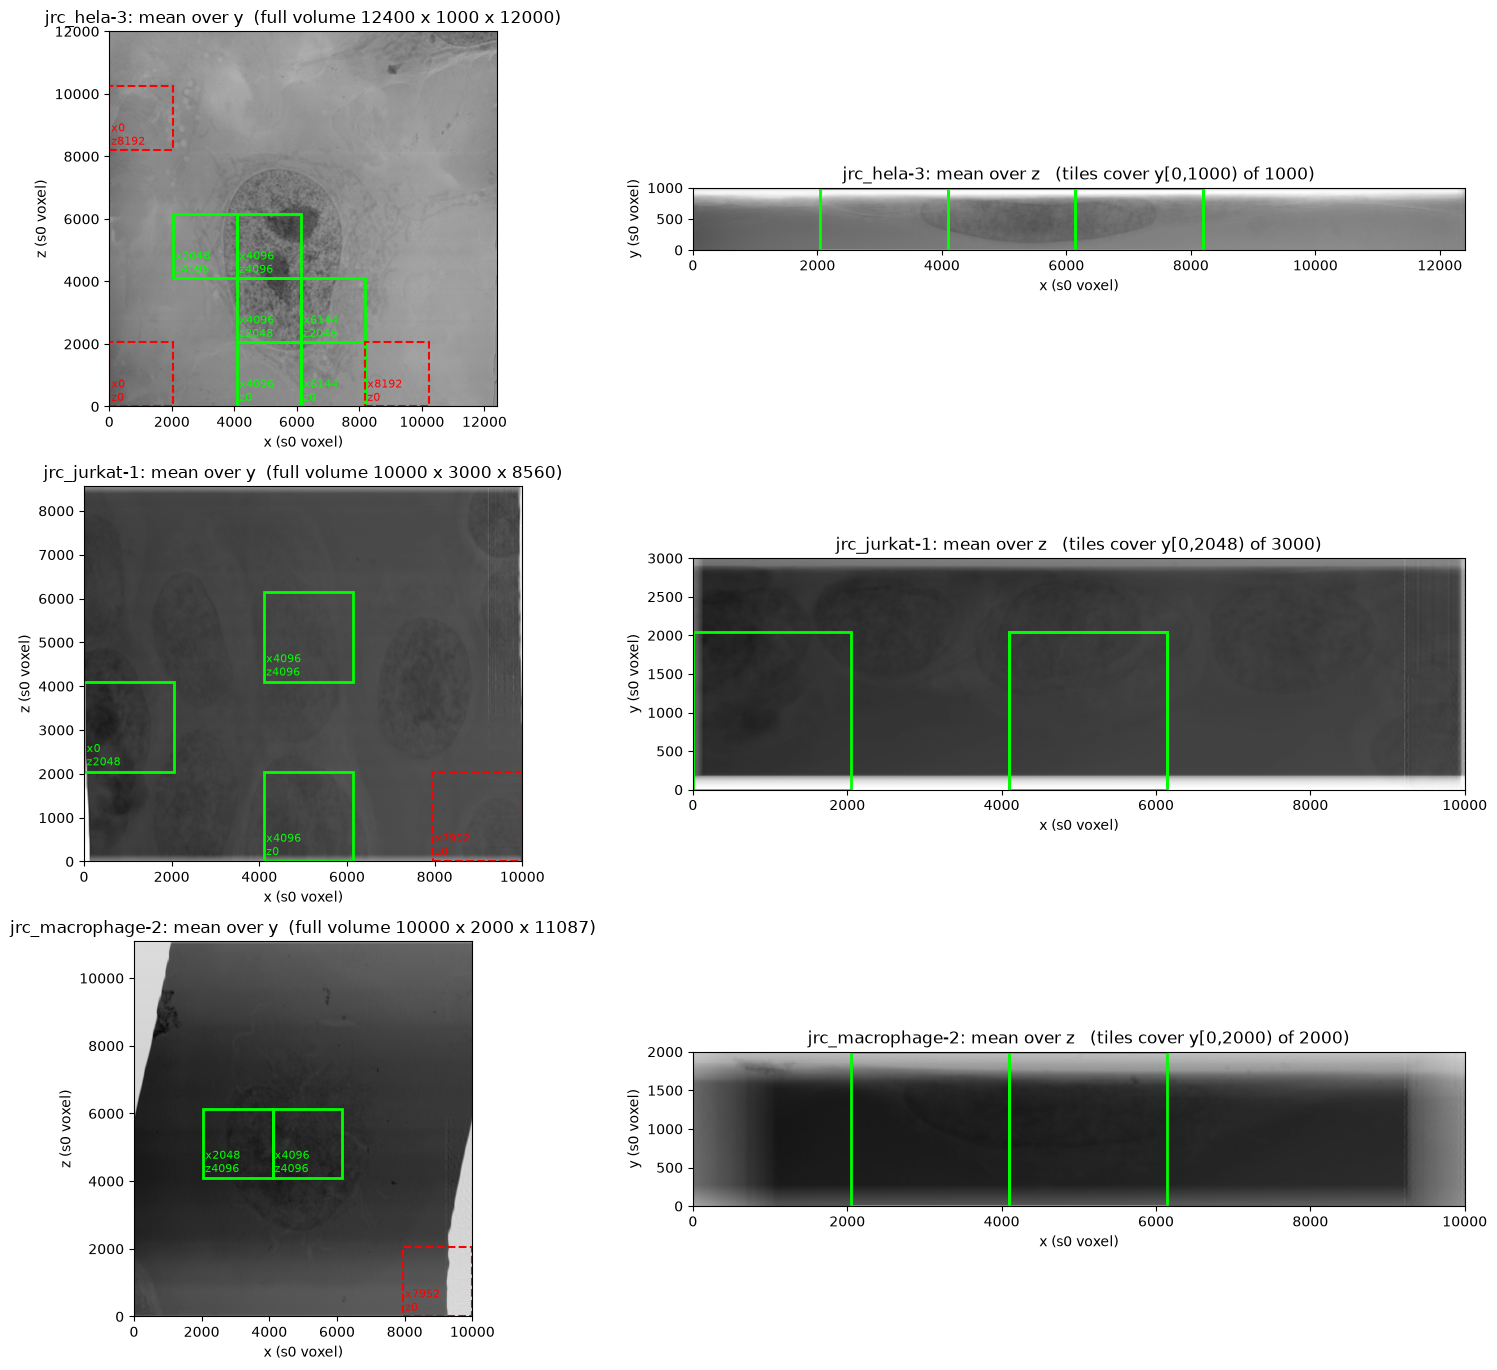

[PASS] no two local tiles overlap  --  0 overlapping pairs
[INFO] face-adjacent tile pairs (used for the seam test)  --  x2048_y0_z4096|x4096_y0_z4096:x, x4096_y0_z0|x4096_y0_z2048:z, x4096_y0_z0|x6144_y0_z0:x, x4096_y0_z2048|x4096_y0_z4096:z, x4096_y0_z2048|x6144_y0_z2048:x, x6144_y0_z0|x6144_y0_z2048:z, x2048_y0_z4096|x4096_y0_z4096:x


In [4]:
def get_mip(ds):
    p = CACHE / f"mip{MIP}_{ds}.npy"
    if p.exists() and not REFRESH:
        return np.load(p)
    if not ONLINE:
        return None
    try:
        from cloudvolume import CloudVolume
        cv = CloudVolume(f"precomputed://{BUCKET}/{ds}/{EM_PATH}", mip=MIP, use_https=True, progress=False,
                         fill_missing=False, parallel=1)
        a = np.ascontiguousarray(cv[:, :, :][..., 0].transpose(2, 1, 0))      # (z, y, x)
        np.save(p, a)
        return a
    except Exception as e:                                                      # noqa: BLE001
        info(f"coarse map of {ds} unavailable", repr(e)[:90])
        return None


F = 2 ** MIP
fig, axes = plt.subplots(len(DS_ORDER), 2, figsize=(16, 4.6 * len(DS_ORDER)))
for r, ds in enumerate(DS_ORDER):
    a = get_mip(ds); X, Y, Z = ONL[ds]["size"]
    ax1, ax2 = axes[r]
    if a is not None:
        vlo, vhi = np.percentile(a, [1, 99.5])
        ax1.imshow(a.mean(1), cmap="gray", origin="lower", extent=(0, a.shape[2] * F, 0, a.shape[0] * F), vmin=vlo, vmax=vhi, aspect="equal")
        ax2.imshow(a.mean(0), cmap="gray", origin="lower", extent=(0, a.shape[2] * F, 0, a.shape[1] * F), vmin=vlo, vmax=vhi, aspect="equal")
        check(f"coarse map extent matches online size [{ds}]", abs(a.shape[2] * F - X) <= F and abs(a.shape[0] * F - Z) <= F and abs(a.shape[1] * F - Y) <= F,
              f"mip{MIP} {a.shape} x{F} vs (z,y,x)=({Z},{Y},{X})")
    for t in [t for t in TILES if t["ds"] == ds]:
        ax1.add_patch(Rectangle((t["x0"], t["z0"]), BOX, BOX, fill=False, ec="lime", lw=2))
        ax1.text(t["x0"] + 60, t["z0"] + 60, f"x{t['x0']}\nz{t['z0']}", color="lime", fontsize=8, va="bottom")
        ax2.add_patch(Rectangle((t["x0"], t["y0"]), BOX, t["shape"][1], fill=False, ec="lime", lw=2))
    for o_ in [o_ for o_ in ORIG if o_["ds"] == ds and not o_["used"]]:
        ax1.add_patch(Rectangle((o_["x0"], o_["z0"]), BOX, BOX, fill=False, ec="red", lw=1.5, ls="--"))
        ax1.text(o_["x0"] + 60, o_["z0"] + 60, f"x{o_['x0']}\nz{o_['z0']}", color="red", fontsize=8, va="bottom")
    ax1.set_xlim(0, X); ax1.set_ylim(0, Z); ax1.set_xlabel("x (s0 voxel)"); ax1.set_ylabel("z (s0 voxel)")
    ax1.set_title(f"{ds}: mean over y  (full volume {X} x {Y} x {Z})")
    ax2.set_xlim(0, X); ax2.set_ylim(0, Y); ax2.set_xlabel("x (s0 voxel)"); ax2.set_ylabel("y (s0 voxel)")
    ax2.set_title(f"{ds}: mean over z   (tiles cover y[0,{max(t['shape'][1] for t in TILES if t['ds']==ds)}) of {Y})")
plt.tight_layout(); plt.show()

# overlaps / adjacency between local tiles of the same dataset (source-voxel coordinates, half-open)
def box_of(t):
    return (t["x0"], t["x0"] + BOX), (t["y0"], t["y0"] + t["shape"][1]), (t["z0"], t["z0"] + BOX)


ADJ = []
n_over = 0
for i, a_ in enumerate(TILES):
    for b_ in TILES[i + 1:]:
        if a_["ds"] != b_["ds"]:
            continue
        ba, bb = box_of(a_), box_of(b_)
        inter = [min(p[1], q[1]) - max(p[0], q[0]) for p, q in zip(ba, bb)]
        if all(v > 0 for v in inter):
            n_over += 1; print("OVERLAP", a_["name"], b_["name"], inter)
        elif sum(v == 0 for v in inter) == 1 and all(v >= 0 for v in inter):
            axis = "xyz"[inter.index(0)]
            ADJ.append((a_, b_, axis)); 
check("no two local tiles overlap", n_over == 0, f"{n_over} overlapping pairs")
info("face-adjacent tile pairs (used for the seam test)", ", ".join(f"{a_['name'].split('_4nm_')[1]}|{b_['name'].split('_4nm_')[1]}:{ax}" for a_, b_, ax in ADJ))


## 4. Patch scan: which regions are meaningful?

Each tile is scanned with a regular grid of probe patches (`SCAN_P`, the SSL training-patch scale). A patch is
**meaningful** when it passes the three gates used for SSL crop cleaning (`LazyVolDataset`, `collect_meaningful_crops.py`):

* `content_frac >= 0.8`: fraction of 4x16x16 blocks whose local std (after the tile's `.norm.json` scaling, exactly as in training) is `>= 0.05`. Rejects flat resin / saturated areas.
* `autocorr >= 0.5`: lag-1 in-plane autocorrelation. Rejects grainy resin / detector noise, which has high local variance but ~white noise (`~0.25`); real ultrastructure is `~0.6-0.9`.
* `nz_frac >= 0.5`: non-zero fraction. Rejects missing-data fill.

Every non-meaningful patch is also given a *reason* (`blank` constant/saturated, `flat`, `grain`), and the same statistics are computed with a plain 0-255 scaling to
expose how sensitive `content_frac` is to the (under-calibrated) sidecar range. Results are cached in `CACHE`.


In [5]:
def grid_origins(shape):
    out = []
    for n, p, s in zip(shape, SCAN_P, SCAN_STRIDE):
        o = list(range(0, n - p + 1, s))
        if o[-1] != n - p:
            o.append(n - p)            # make sure the last rows / slices / columns (cell edge!) are covered
        out.append(np.array(o))
    return out


def cell_edges(o, p, n):
    """Partition [0, n) into cells, one per patch origin o (cuts halfway between neighbouring patch centres)."""
    c = o + p / 2.0
    return np.concatenate([[0], (c[:-1] + c[1:]) / 2.0, [n]])


def patch_metrics(p, lo, hi):
    pf = p.astype(np.float32)
    n01 = np.clip((pf - lo) / max(hi - lo, 1.0), 0, 1)          # scaling used in training (sidecar)
    f01 = pf / 255.0                                             # plain dtype range
    return (content_fraction(n01, CONTENT_STD), lag1_autocorr(n01), content_fraction(f01, CONTENT_STD), lag1_autocorr(f01),
            float(np.mean(p != 0)), float(np.mean((p < lo) | (p > hi))), float(pf.mean()), float(pf.std()),
            float(np.mean(p == 255)), float(np.mean(p == 0)))


METRIC_NAMES = ["cf", "ac", "cf_full", "ac_full", "nz", "oor", "mean", "std", "sat255", "sat0"]


def scan_tile(t):
    d = vol(t["file"]); lo, hi = t["norm"]["min"], t["norm"]["max"]
    zs, ys, xs = grid_origins(d.shape)
    sig = f"{SCAN_P}-{SCAN_STRIDE}-{CONTENT_STD}-{int(t['file'].stat().st_mtime)}-{lo}-{hi}".replace(" ", "")
    cp = CACHE / f"scan_{t['name']}.npz"
    if cp.exists() and not REFRESH:
        z_ = np.load(cp, allow_pickle=True)
        if str(z_["sig"]) == sig:
            return dict(zs=zs, ys=ys, xs=xs, M=z_["M"], hist=z_["hist"], cached=True)
    P = SCAN_P
    M = np.zeros((len(zs), len(ys), len(xs), len(METRIC_NAMES)), np.float32)
    hist = np.zeros(256, np.int64)
    with ThreadPoolExecutor(THREADS) as ex:
        for iz, z in enumerate(zs):
            blk = d[z:z + P[0]]
            hist += np.bincount(blk[::2, ::2, ::2].ravel(), minlength=256)
            futs = {(iy, ix): ex.submit(patch_metrics, blk[:, y:y + P[1], x:x + P[2]], lo, hi)
                    for iy, y in enumerate(ys) for ix, x in enumerate(xs)}
            for (iy, ix), fu in futs.items():
                M[iz, iy, ix] = fu.result()
    np.savez(cp, sig=sig, M=M, hist=hist)
    return dict(zs=zs, ys=ys, xs=xs, M=M, hist=hist, cached=False)


t0 = time.time()
for t in TILES:
    t1 = time.time()
    t["scan"] = scan_tile(t)
    S = t["scan"]
    print(f"{t['name']:44s} grid {S['M'].shape[:3]} = {np.prod(S['M'].shape[:3]):5d} patches  "
          f"{'(cached)' if S['cached'] else f'{time.time()-t1:5.0f}s'}")
print(f"scan total {time.time()-t0:.0f}s")


def classify(M):
    """0 = meaningful, 1 = blank (constant / saturated), 2 = flat, 3 = grain; also returns pass mask."""
    cf, ac, nz, std, s255, s0 = (M[..., METRIC_NAMES.index(k)] for k in ("cf", "ac", "nz", "std", "sat255", "sat0"))
    ok = (cf >= MIN_CONTENT) & (ac >= MIN_AC) & (nz >= MIN_NZ)
    cls = np.zeros(cf.shape, np.int8)
    blank = (std < 1.0) | (s255 + s0 > 0.5)
    cls[~ok & ~blank & (cf < MIN_CONTENT)] = 2
    cls[~ok & ~blank & (cf >= MIN_CONTENT)] = 3
    cls[~ok & blank] = 1
    cls[~ok & (cls == 0)] = 3                  # nz gate only
    return ok, cls


CLS_NAMES = ["meaningful", "blank", "flat", "grain"]
print()
print(f"{'tile':44s} {'meaningful':>10s} {'blank':>7s} {'flat':>7s} {'grain':>7s}   {'cf med':>6s} {'ac med':>6s} {'ac med (0-255 scaling)':>22s} {'cf@0-255':>8s}")
for t in TILES:
    M = t["scan"]["M"]; ok, cls = classify(M); t["ok"], t["cls"] = ok, cls
    fr = [float(np.mean(cls == k)) for k in range(4)]; t["frac_cls"] = fr
    t["pass_frac"] = fr[0]
    print(f"{t['name']:44s} {fr[0]:10.2f} {fr[1]:7.2f} {fr[2]:7.2f} {fr[3]:7.2f}   "
          f"{np.median(M[..., 0]):6.2f} {np.median(M[..., 1]):6.2f} {np.median(M[..., 3]):22.2f} {np.mean(M[..., 2]):8.2f}")


jrc_hela-3_4nm_x2048_y0_z4096                grid (10, 8, 9) =   720 patches  (cached)
jrc_hela-3_4nm_x4096_y0_z0                   grid (10, 8, 9) =   720 patches  (cached)
jrc_hela-3_4nm_x4096_y0_z2048                grid (10, 8, 9) =   720 patches  (cached)
jrc_hela-3_4nm_x4096_y0_z4096                grid (10, 8, 9) =   720 patches  (cached)
jrc_hela-3_4nm_x6144_y0_z0                   grid (10, 8, 9) =   720 patches  (cached)
jrc_hela-3_4nm_x6144_y0_z2048                grid (10, 8, 9) =   720 patches  (cached)
jrc_jurkat-1_4nm_x0_y0_z2048                 grid (10, 16, 9) =  1440 patches  (cached)
jrc_jurkat-1_4nm_x4096_y0_z0                 grid (10, 16, 9) =  1440 patches  (cached)
jrc_jurkat-1_4nm_x4096_y0_z4096              grid (10, 16, 9) =  1440 patches  (cached)
jrc_macrophage-2_4nm_x2048_y0_z4096          grid (10, 16, 9) =  1440 patches  (cached)
jrc_macrophage-2_4nm_x4096_y0_z4096          grid (10, 16, 9) =  1440 patches  (cached)
scan total 0s

tile                   

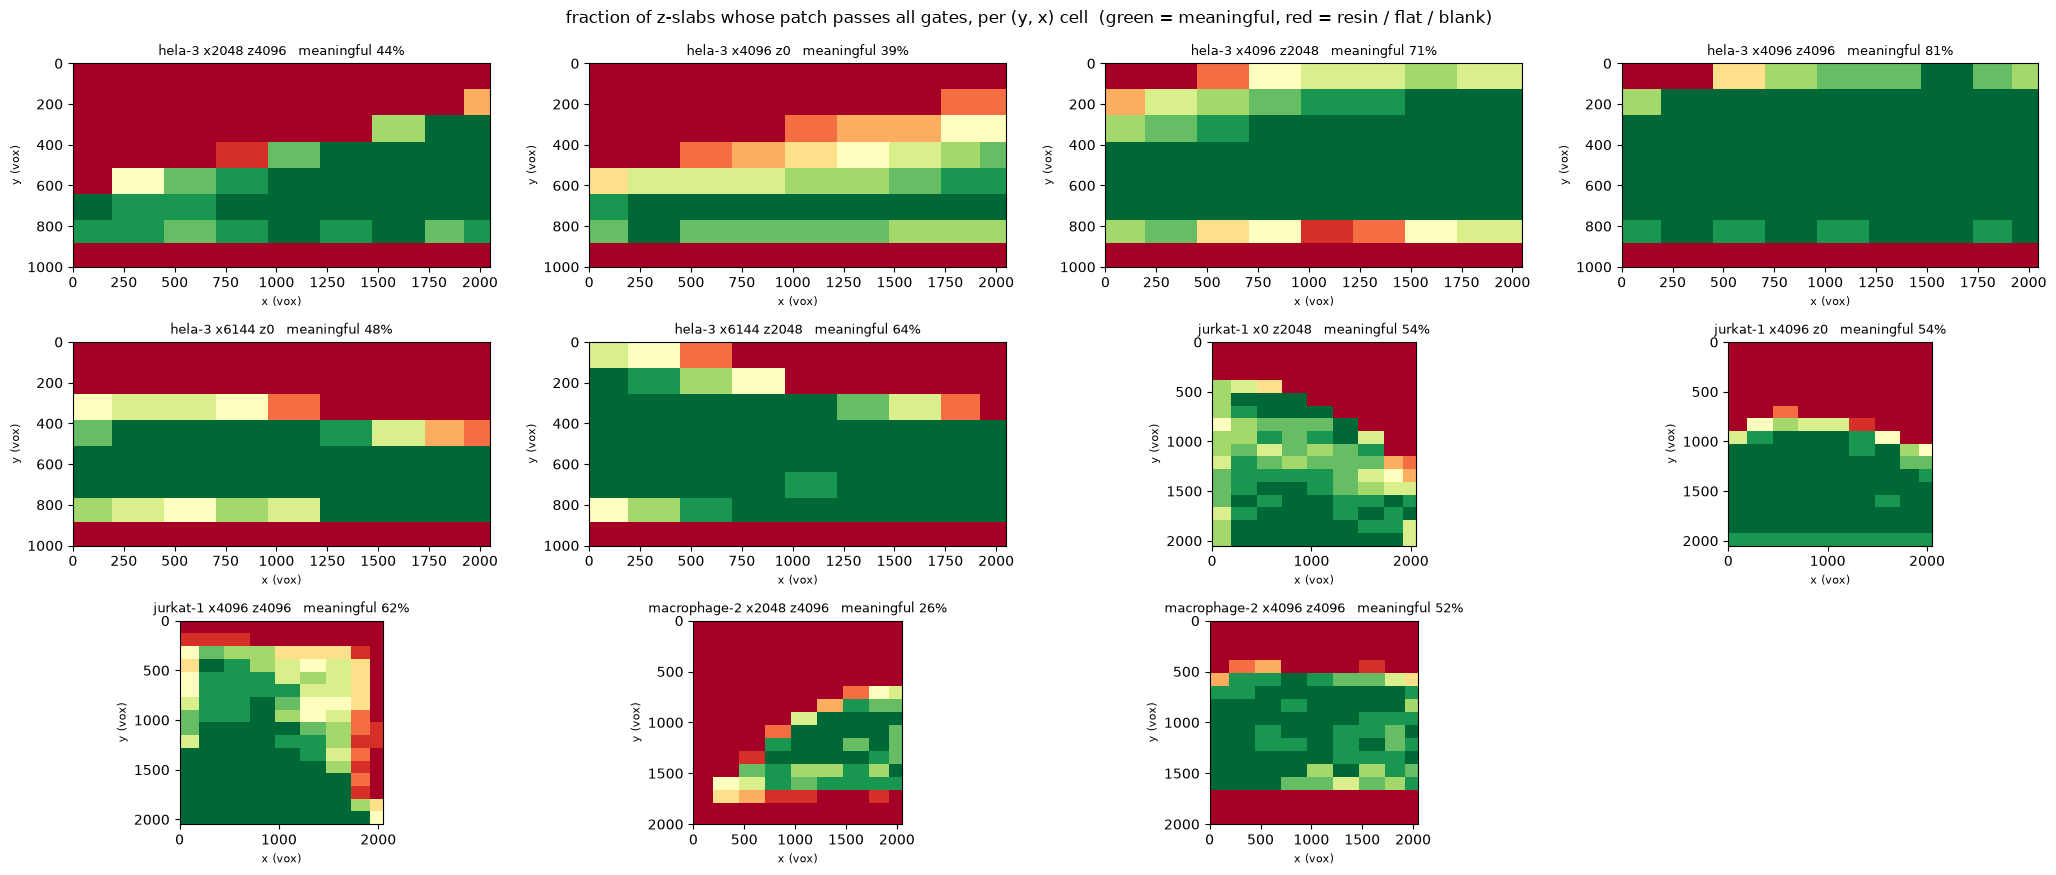

In [6]:
# gate maps: fraction of meaningful patches along z for each (y, x) cell, and along (y) / (z) as profiles
n = len(TILES); cols = 4; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5.2 * cols, 2.9 * rows)); axes = np.atleast_1d(axes).ravel()
for ax, t in zip(axes, TILES):
    S = t["scan"]; Z, Y, X = t["shape"]
    ex_ = cell_edges(S["xs"], SCAN_P[2], X); ey_ = cell_edges(S["ys"], SCAN_P[1], Y)
    im = ax.pcolormesh(ex_, ey_, t["ok"].mean(0), vmin=0, vmax=1, cmap="RdYlGn", shading="flat")
    ax.invert_yaxis(); ax.set_aspect("equal")
    ax.set_title(f"{t['ds'].replace('jrc_','')} x{t['x0']} z{t['z0']}   meaningful {t['pass_frac']:.0%}", fontsize=9)
    ax.set_xlabel("x (vox)", fontsize=8); ax.set_ylabel("y (vox)", fontsize=8)
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("fraction of z-slabs whose patch passes all gates, per (y, x) cell  (green = meaningful, red = resin / flat / blank)", y=1.0)
plt.tight_layout(); plt.show()


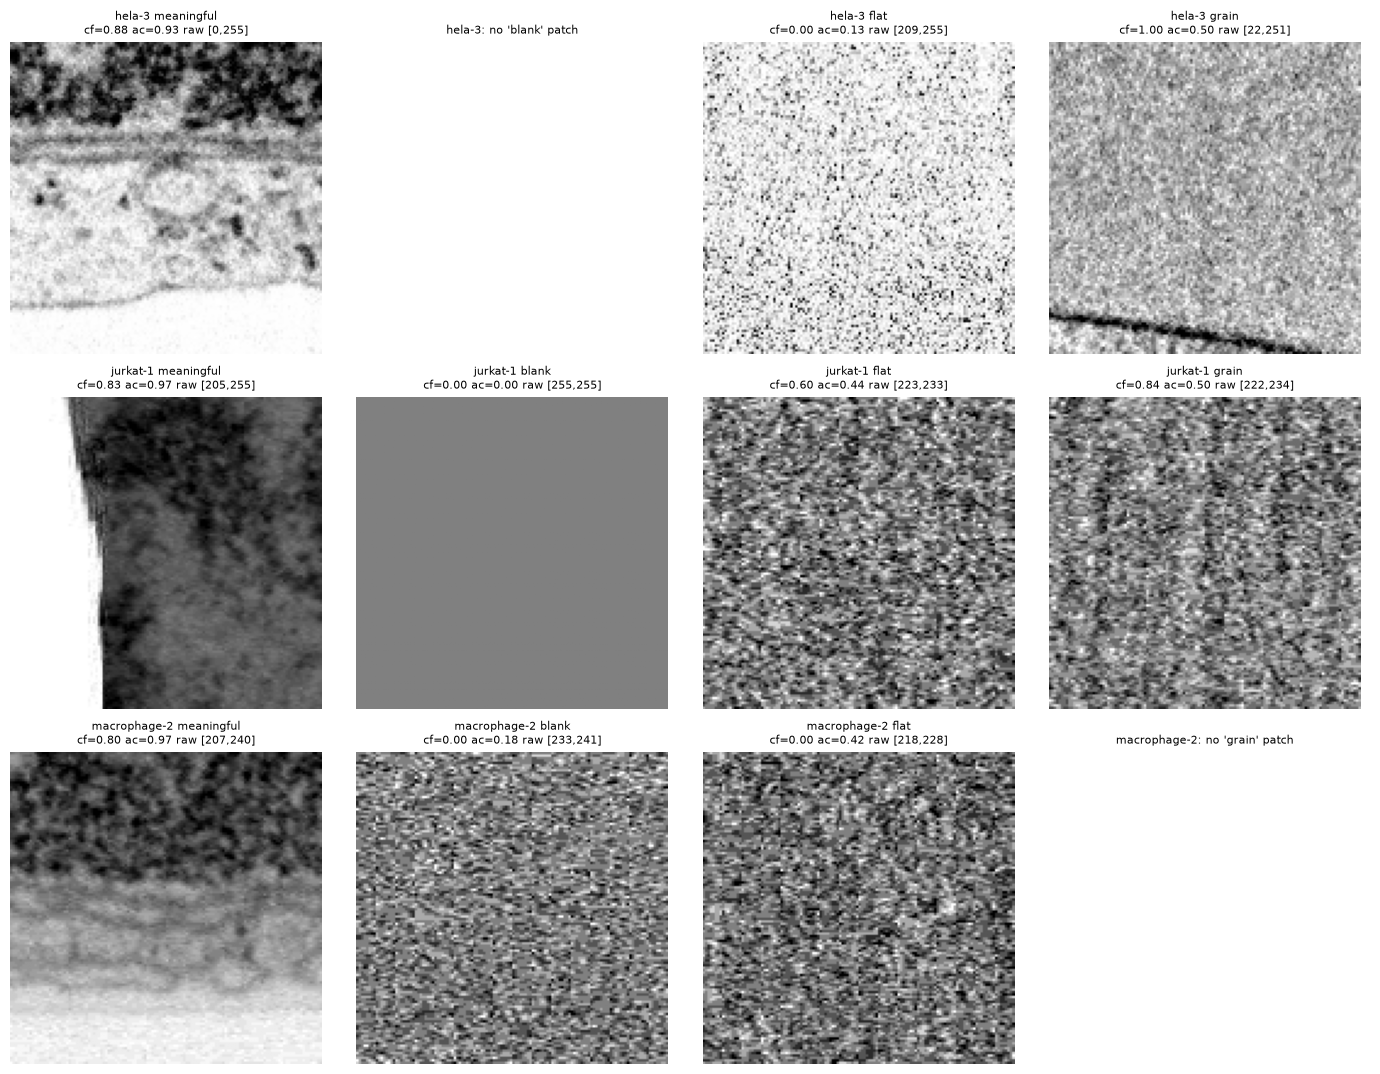

In [7]:
# what do the four patch classes look like?  one example each from the files where they occur
def get_patch(t, iz, iy, ix):
    S = t["scan"]; z, y, x = int(S["zs"][iz]), int(S["ys"][iy]), int(S["xs"][ix])
    return vol(t["file"])[z + SCAN_P[0] // 2, y:y + SCAN_P[1], x:x + SCAN_P[2]], (z, y, x)


want = {0: "meaningful", 1: "blank", 2: "flat", 3: "grain"}
fig, axes = plt.subplots(len(DS_ORDER), 4, figsize=(14, 3.6 * len(DS_ORDER)))
for r, ds in enumerate(DS_ORDER):
    ts = [t for t in TILES if t["ds"] == ds]
    for k in want:
        c = k; ax = axes[r, c]; ax.axis("off")
        best = None
        for t in ts:                                    # pick the most typical example: highest ac for meaningful, else most extreme
            idx = np.argwhere(t["cls"] == k)
            if len(idx):
                key = [t["scan"]["M"][tuple(i)][1] for i in idx]
                j = int(np.argmax(key)) if k in (0, 3) else int(np.argmin(key))
                cand = (key[j], t, tuple(idx[j]))
                best = cand if best is None or (cand[0] > best[0] if k in (0, 3) else cand[0] < best[0]) else best
        if best is None:
            ax.set_title(f"{ds.replace('jrc_','')}: no '{want[k]}' patch", fontsize=8); continue
        _, t, (iz, iy, ix) = best
        p, org = get_patch(t, iz, iy, ix)
        lo, hi = np.percentile(p, [0.5, 99.5]) if p.std() > 0 else (int(p.min()) - 1, int(p.min()) + 1)
        ax.imshow(p, cmap="gray", vmin=lo, vmax=max(hi, lo + 1))
        M = t["scan"]["M"][iz, iy, ix]
        ax.set_title(f"{ds.replace('jrc_','')} {want[k]}\ncf={M[0]:.2f} ac={M[1]:.2f} raw [{p.min()},{p.max()}]", fontsize=8)
plt.tight_layout(); plt.show()


## 5. Intensity range and `.norm.json` calibration

`.norm.json` holds the `min`/`max` used to scale a tile to `[0, 1]` in training. The histograms come from the patch scan
(every 2nd voxel of every scanned slab). A sidecar that is much narrower than the data clips real signal; one that is much wider than the
data wastes dynamic range (and changes `content_frac`, which uses an absolute threshold).


tile                                           norm.json  observed min..max  p0.1..p99.9  % < lo  % > hi  % ==0  % ==255 levels>0.01%
jrc_hela-3_4nm_x2048_y0_z4096                     0..255             0..255       1..255    0.00    0.00   0.08     2.53          256
jrc_hela-3_4nm_x4096_y0_z0                        0..255             0..255       1..255    0.00    0.00   0.08     3.50          256
jrc_hela-3_4nm_x4096_y0_z2048                     0..255             0..255       0..255    0.00    0.00   0.49     3.88          256
jrc_hela-3_4nm_x4096_y0_z4096                     0..255             0..255       0..255    0.00    0.00   0.42     3.56          256
jrc_hela-3_4nm_x6144_y0_z0                        0..255             0..255       1..255    0.00    0.00   0.08     4.39          256
jrc_hela-3_4nm_x6144_y0_z2048                     0..255             0..255       0..255    0.00    0.00   0.20     4.01          256
jrc_jurkat-1_4nm_x0_y0_z2048                    205..237      

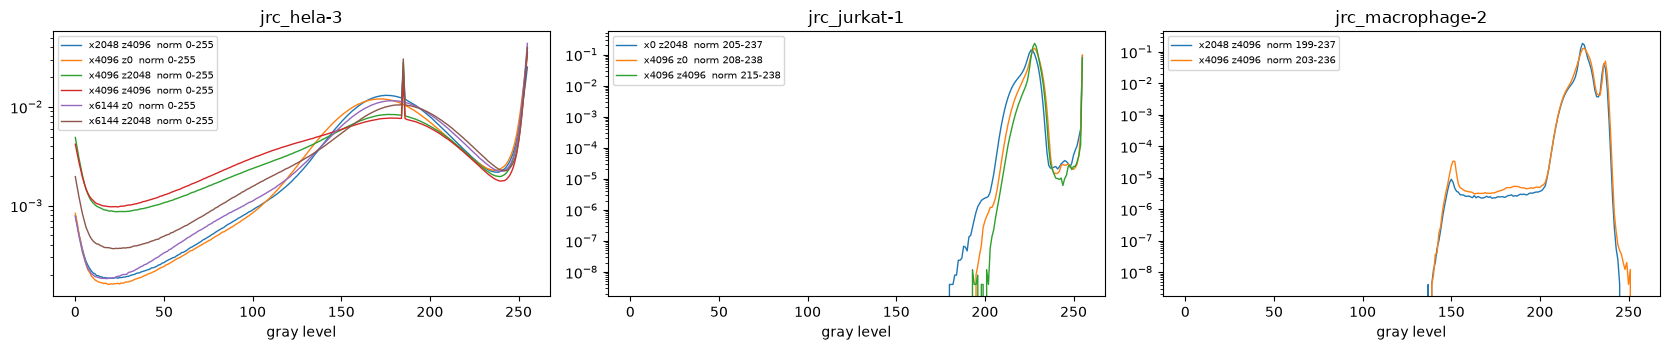


[PASS] norm.json is the documented 0..255 [jrc_hela-3_4nm_x2048_y0_z4096]  --  actual 0..255
[PASS] norm.json covers >= 97 % of voxels [jrc_hela-3_4nm_x2048_y0_z4096]  --  0.0 % outside; 0.0 % above max
[PASS] saturation at 255 < 5 % [jrc_hela-3_4nm_x2048_y0_z4096]  --  2.5 % of voxels == 255
[PASS] norm.json is the documented 0..255 [jrc_hela-3_4nm_x4096_y0_z0]  --  actual 0..255
[PASS] norm.json covers >= 97 % of voxels [jrc_hela-3_4nm_x4096_y0_z0]  --  0.0 % outside; 0.0 % above max
[PASS] saturation at 255 < 5 % [jrc_hela-3_4nm_x4096_y0_z0]  --  3.5 % of voxels == 255
[PASS] norm.json is the documented 0..255 [jrc_hela-3_4nm_x4096_y0_z2048]  --  actual 0..255
[PASS] norm.json covers >= 97 % of voxels [jrc_hela-3_4nm_x4096_y0_z2048]  --  0.0 % outside; 0.0 % above max
[PASS] saturation at 255 < 5 % [jrc_hela-3_4nm_x4096_y0_z2048]  --  3.9 % of voxels == 255
[PASS] norm.json is the documented 0..255 [jrc_hela-3_4nm_x4096_y0_z4096]  --  actual 0..255
[PASS] norm.json covers >= 97 % o

In [8]:
print(f"{'tile':44s} {'norm.json':>11s} {'observed min..max':>18s} {'p0.1..p99.9':>12s} {'% < lo':>7s} {'% > hi':>7s} {'% ==0':>6s} {'% ==255':>8s} {'levels>0.01%':>12s}")
fig, axes = plt.subplots(1, len(DS_ORDER), figsize=(5.6 * len(DS_ORDER), 3.6))
axes = np.atleast_1d(axes)
for t in TILES:
    h = t["scan"]["hist"].astype(np.float64); p = h / h.sum(); cdf = np.cumsum(p)
    lo, hi = int(t["norm"]["min"]), int(t["norm"]["max"])
    nz_ = np.nonzero(h)[0]
    q = lambda f: int(np.searchsorted(cdf, f))
    t["stat"] = dict(obs_min=int(nz_[0]), obs_max=int(nz_[-1]), p001=q(0.001), p999=q(0.999), below=float(p[:lo].sum()),
                     above=float(p[hi + 1:].sum()), z=float(p[0]), s=float(p[255]), levels=int((p > 1e-4).sum()))
    s = t["stat"]
    print(f"{t['name']:44s} {f'{lo}..{hi}':>11s} {f'{s['obs_min']}..{s['obs_max']}':>18s} {f'{s['p001']}..{s['p999']}':>12s} "
          f"{100*s['below']:7.2f} {100*s['above']:7.2f} {100*s['z']:6.2f} {100*s['s']:8.2f} {s['levels']:12d}")
    axes[DS_ORDER.index(t["ds"])].plot(np.arange(256), p, lw=1, label=f"x{t['x0']} z{t['z0']}  norm {lo}-{hi}")
for ax, ds in zip(axes, DS_ORDER):
    ax.set_yscale("log"); ax.set_xlabel("gray level"); ax.set_title(ds); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

print()
for t in TILES:
    s = t["stat"]
    check(f"norm.json is the documented 0..255 [{t['name']}]", t["norm"]["min"] == 0 and t["norm"]["max"] == 255,
          f"actual {t['norm']['min']:.0f}..{t['norm']['max']:.0f}", warn=True)
    check(f"norm.json covers >= 97 % of voxels [{t['name']}]", s["below"] + s["above"] < 0.03,
          f"{100*(s['below']+s['above']):.1f} % outside; {100*s['above']:.1f} % above max", warn=True)
    check(f"saturation at 255 < 5 % [{t['name']}]", s["s"] < 0.05, f"{100*s['s']:.1f} % of voxels == 255", warn=True)


In [9]:
# is the 255 saturation spread over the tile or concentrated in blank patches?  (Jurkat shows 12-14 %)
print(f"{'tile':44s} {'sat255 overall':>14s} {'in blank patches':>17s} {'in meaningful patches':>22s} {'meaningful patch sat255 (median)':>34s}")
for t in TILES:
    M = t["scan"]["M"]; s255 = M[..., 8]; cls = t["cls"]
    tot = s255.mean()
    share_blank = s255[cls == 1].sum() / max(s255.sum(), 1e-9)
    share_ok = s255[cls == 0].sum() / max(s255.sum(), 1e-9)
    print(f"{t['name']:44s} {100*tot:13.1f}% {100*share_blank:16.0f}% {100*share_ok:21.0f}% {100*np.median(s255[cls==0]) if (cls==0).any() else float('nan'):33.2f}%")


tile                                         sat255 overall  in blank patches  in meaningful patches   meaningful patch sat255 (median)
jrc_hela-3_4nm_x2048_y0_z4096                          2.7%                0%                     8%                              0.03%
jrc_hela-3_4nm_x4096_y0_z0                             3.9%                0%                     8%                              0.07%
jrc_hela-3_4nm_x4096_y0_z2048                          4.6%                0%                    10%                              0.03%
jrc_hela-3_4nm_x4096_y0_z4096                          3.8%                0%                     8%                              0.02%
jrc_hela-3_4nm_x6144_y0_z0                             4.8%                0%                     7%                              0.07%
jrc_hela-3_4nm_x6144_y0_z2048                          4.6%                0%                    15%                              0.06%
jrc_jurkat-1_4nm_x0_y0_z2048                    

## 6. Resample integrity: 4 nm tiles vs the anisotropic originals

`resample_cosem_isotropic.py` resamples `z` only (trilinear). For several output slices `k`, the 4 nm slice is compared with the original
slices interpolated at `k * 4 / rz` (corner-aligned) and at `(k + 0.5) * 4 / rz - 0.5` (half-pixel-aligned), to verify both orientation
and which sampling convention was used. A correct resample gives `NCC ~ 1` and a small mean abs diff for one of them.


In [10]:
def src_for(t):
    for o_ in ORIG:
        if (o_["ds"], o_["x0"], o_["y0"], o_["z0"]) == (t["ds"], t["x0"], t["y0"], t["z0"]):
            return o_
    return None


RES = []
if not ORIG:
    info("originals not available: resample integrity skipped")
else:
    print(f"{'tile':44s} {'k':>5s} {'ncc corner':>10s} {'mad corner':>10s} {'ncc half':>9s} {'mad half':>9s}  {'ncc to wrong z (k+30)':>22s}")
    for t in TILES:
        o_ = src_for(t); d4 = vol(t["file"]); dr = vol(o_["file"]); rz = o_["rz"]
        n4 = d4.shape[0]
        out = []
        for k in np.linspace(40, n4 - 41, 4).astype(int):
            a = d4[k, ::2, ::2].astype(np.float32)
            res = []
            for pos in (k * 4.0 / rz, (k + 0.5) * 4.0 / rz - 0.5):
                i0 = int(np.floor(pos)); w = pos - i0
                s0_ = dr[i0, ::2, ::2].astype(np.float32); s1_ = dr[min(i0 + 1, dr.shape[0] - 1), ::2, ::2].astype(np.float32)
                b = (1 - w) * s0_ + w * s1_
                res.append((ncc(a, b), float(np.abs(a - b).mean())))
            wrong = ncc(a, dr[int((k + 30) * 4.0 / rz), ::2, ::2])
            out.append((k, res, wrong))
            print(f"{t['name']:44s} {k:5d} {res[0][0]:10.4f} {res[0][1]:10.2f} {res[1][0]:9.4f} {res[1][1]:9.2f}  {wrong:22.3f}")
        best_ncc = np.mean([max(r[0][0], r[1][0]) for _, r, _ in out]); best_mad = np.mean([min(r[0][1], r[1][1]) for _, r, _ in out])
        mode = "half-pixel" if np.mean([r[1][1] < r[0][1] for _, r, _ in out]) > 0.5 else "corner"
        RES.append((t["name"], best_ncc, best_mad, mode))
        check(f"4nm tile == z-resampled original (NCC > 0.99) [{t['name']}]", best_ncc > 0.99, f"ncc={best_ncc:.4f} mad={best_mad:.2f} grey levels, {mode}-aligned")


tile                                             k ncc corner mad corner  ncc half  mad half   ncc to wrong z (k+30)
jrc_hela-3_4nm_x2048_y0_z4096                   40     0.9966       2.40    1.0000      0.24                   0.493
jrc_hela-3_4nm_x2048_y0_z4096                  566     0.9991       1.45    0.9994      1.19                   0.467
jrc_hela-3_4nm_x2048_y0_z4096                 1092     0.9999       0.54    0.9978      2.19                   0.414
jrc_hela-3_4nm_x2048_y0_z4096                 1618     0.9998       0.59    0.9942      3.24                   0.381
[PASS] 4nm tile == z-resampled original (NCC > 0.99) [jrc_hela-3_4nm_x2048_y0_z4096]  --  ncc=0.9998 mad=0.64 grey levels, corner-aligned
jrc_hela-3_4nm_x4096_y0_z0                      40     0.9959       2.65    1.0000      0.25                   0.466
jrc_hela-3_4nm_x4096_y0_z0                     566     0.9986       1.62    0.9992      1.31                   0.447
jrc_hela-3_4nm_x4096_y0_z0                 

## 7. Seams between face-adjacent tiles, and z-continuity inside each tile

Tiles that touch (section 3) should be a continuation of one another: the correlation of the two faces across the seam must be as high as the correlation of two
neighbouring planes inside a tile. Then, inside each tile, a thin `(128 x 128)` column through the most structured patch is read for **all** `z`
and the correlation of consecutive slices is tracked to catch blank, duplicated or jumping slices (FIB-SEM drift / milling hiccups) that a sparse patch scan cannot see.


In [11]:
def face(t, axis, which):
    d = vol(t["file"])
    if axis == "z":
        return d[0 if which == "lo" else -1, :, :], d[1 if which == "lo" else -2, :, :]
    if axis == "x":
        i = 0 if which == "lo" else d.shape[2] - 1; j = 1 if which == "lo" else d.shape[2] - 2
        return d[:, :, i], d[:, :, j]


print(f"{'pair (A | B)':64s} {'axis':>4s} {'ncc across seam':>16s} {'ncc inside A':>13s} {'ncc inside B':>13s} {'mean|dA-B|':>11s}")
for a_, b_, ax in ADJ:
    if ax == "y":
        continue
    A, B = (a_, b_) if (a_["z0"] < b_["z0"] if ax == "z" else a_["x0"] < b_["x0"]) else (b_, a_)
    fa, fa2 = face(A, ax, "hi"); fb, fb2 = face(B, ax, "lo")
    seam = ncc(fa, fb); ina = ncc(fa, fa2); inb = ncc(fb, fb2)
    mad = float(np.abs(fa.astype(np.float32) - fb.astype(np.float32)).mean())
    label = f"{A['name'].split('_4nm_')[1].replace('_volume','')} | {B['name'].split('_4nm_')[1].replace('_volume','')}  [{A['ds'].replace('jrc_','')}]"
    print(f"{label:64s} {ax:>4s} {seam:16.3f} {ina:13.3f} {inb:13.3f} {mad:11.2f}")
    check(f"seam continuity {ax}: {label}", seam > 0.8 * min(ina, inb), f"seam {seam:.3f} vs inside {ina:.3f}/{inb:.3f}", warn=True)


pair (A | B)                                                     axis  ncc across seam  ncc inside A  ncc inside B  mean|dA-B|
x2048_y0_z4096 | x4096_y0_z4096  [hela-3]                           x            0.888         0.886         0.886       19.75
[PASS] seam continuity x: x2048_y0_z4096 | x4096_y0_z4096  [hela-3]  --  seam 0.888 vs inside 0.886/0.886
x4096_y0_z0 | x4096_y0_z2048  [hela-3]                              z            0.868         0.894         0.895       20.85
[PASS] seam continuity z: x4096_y0_z0 | x4096_y0_z2048  [hela-3]  --  seam 0.868 vs inside 0.894/0.895
x4096_y0_z0 | x6144_y0_z0  [hela-3]                                 x            0.840         0.837         0.838       20.47
[PASS] seam continuity x: x4096_y0_z0 | x6144_y0_z0  [hela-3]  --  seam 0.840 vs inside 0.837/0.838
x4096_y0_z2048 | x4096_y0_z4096  [hela-3]                           z            0.896         0.915         0.916       21.11
[PASS] seam continuity z: x4096_y0_z2048 | x4096_y0_z409

[PASS] no blank / duplicated slices in column y768 x1792 [jrc_hela-3_4nm_x2048_y0_z4096]  --  dup=0 blank=0
[PASS] no slice-to-slice NCC outliers [jrc_hela-3_4nm_x2048_y0_z4096]  --  median ncc 0.925, outliers at z=[]
[PASS] no blank / duplicated slices in column y384 x1536 [jrc_hela-3_4nm_x4096_y0_z0]  --  dup=0 blank=0
[WARN] no slice-to-slice NCC outliers [jrc_hela-3_4nm_x4096_y0_z0]  --  median ncc 0.598, outliers at z=[0, 1, 2, 3, 4, 5]
[PASS] no blank / duplicated slices in column y768 x256 [jrc_hela-3_4nm_x4096_y0_z2048]  --  dup=0 blank=0
[PASS] no slice-to-slice NCC outliers [jrc_hela-3_4nm_x4096_y0_z2048]  --  median ncc 0.914, outliers at z=[]
[PASS] no blank / duplicated slices in column y768 x256 [jrc_hela-3_4nm_x4096_y0_z4096]  --  dup=0 blank=0
[PASS] no slice-to-slice NCC outliers [jrc_hela-3_4nm_x4096_y0_z4096]  --  median ncc 0.924, outliers at z=[]
[PASS] no blank / duplicated slices in column y384 x0 [jrc_hela-3_4nm_x6144_y0_z0]  --  dup=0 blank=0
[WARN] no slice-to

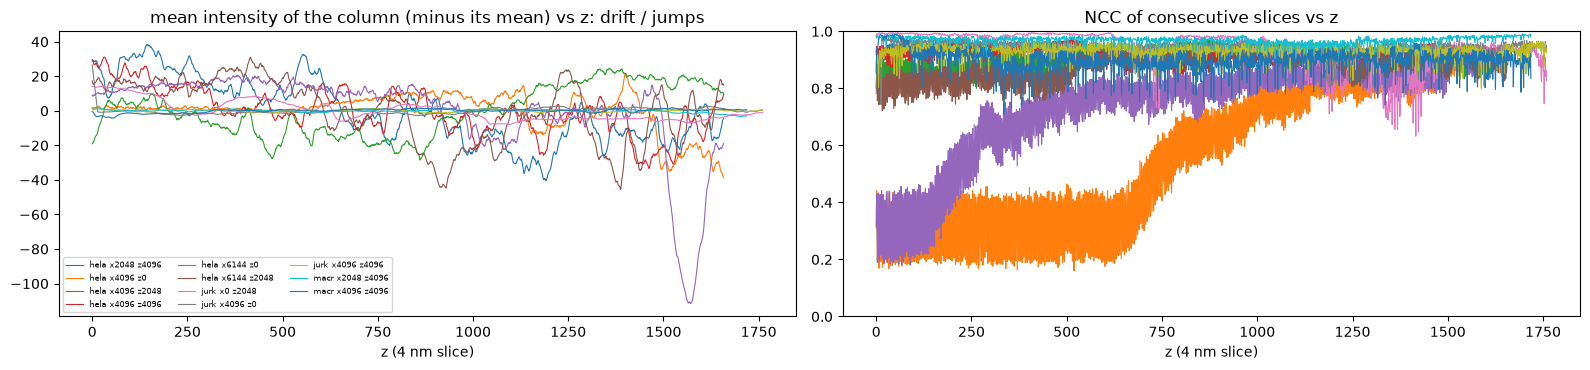

In [12]:
# z-continuity: all slices of a 128 x 128 column through the best (most structured, passing) patch
ZPROF = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for t in TILES:
    M = t["scan"]["M"]; S = t["scan"]
    sc = np.where(t["ok"], M[..., 1], -1)
    iz, iy, ix = np.unravel_index(int(np.argmax(sc)), sc.shape)
    y, x = int(S["ys"][iy]), int(S["xs"][ix])
    col = vol(t["file"])[:, y:y + 128, x:x + 128].astype(np.float32)
    m = col.mean((1, 2)); nccs = np.array([ncc(col[i], col[i + 1]) for i in range(len(col) - 1)])
    dup = np.nonzero(np.abs(col[1:] - col[:-1]).mean((1, 2)) < 1e-6)[0]
    blank = np.nonzero(col.std((1, 2)) < 0.5)[0]
    med = np.median(nccs); bad = np.nonzero(nccs < med - 0.15)[0]
    ZPROF[t["name"]] = dict(yx=(y, x), med=med, bad=bad, dup=dup, blank=blank)
    axes[0].plot(m - m.mean(), lw=0.8, label=f"{t['ds'][4:8]} x{t['x0']} z{t['z0']}")
    axes[1].plot(nccs, lw=0.8)
    check(f"no blank / duplicated slices in column y{y} x{x} [{t['name']}]", len(dup) == 0 and len(blank) == 0, f"dup={len(dup)} blank={len(blank)}")
    check(f"no slice-to-slice NCC outliers [{t['name']}]", len(bad) == 0, f"median ncc {med:.3f}, outliers at z={bad[:6].tolist()}", warn=True)
axes[0].set_title("mean intensity of the column (minus its mean) vs z: drift / jumps"); axes[0].set_xlabel("z (4 nm slice)"); axes[0].legend(fontsize=6, ncol=3)
axes[1].set_title("NCC of consecutive slices vs z"); axes[1].set_xlabel("z (4 nm slice)"); axes[1].set_ylim(0, 1.0)
plt.tight_layout(); plt.show()


## 8. Meaningful regions: the largest box that is (almost) all structure

Whole tiles are the wrong unit: HeLa tiles contain the cell **and** the resin above it, Jurkat / macrophage tiles contain flat resin and saturated borders.
Each patch of the grid owns a cell of the tile (cuts halfway between neighbouring patch centres; `z` is only sampled every `SCAN_STRIDE[0]` slices, so the `z` extent is a coarse estimate).
For every tile the **largest axis-aligned box in which at least `BOX_MIN_PASS` of the volume is meaningful** and which is at least `BOX_MIN_ZYX` large is found exhaustively with 3-D prefix sums.
Verdict: `KEEP` (box covers `>= KEEP_FRAC` of the tile), `CROP` (`>= CROP_FRAC`: use only the box), otherwise `DROP`.


In [13]:
def best_box(t):
    S = t["scan"]; Z, Y, X = t["shape"]
    ez, ey, ex_ = cell_edges(S["zs"], SCAN_P[0], Z), cell_edges(S["ys"], SCAN_P[1], Y), cell_edges(S["xs"], SCAN_P[2], X)
    dz, dy, dx = np.diff(ez), np.diff(ey), np.diff(ex_)
    V = dz[:, None, None] * dy[None, :, None] * dx[None, None, :]
    W = V * t["ok"]
    pad = lambda a: np.pad(a.cumsum(0).cumsum(1).cumsum(2), ((1, 0), (1, 0), (1, 0)))
    PV, PW = pad(V), pad(W)
    nz_, ny_, nx_ = V.shape
    best = None
    xa, xb = np.triu_indices(nx_ + 1, 1)                       # x edge pairs a < b
    ext_x = ex_[xb] - ex_[xa]
    okx = ext_x >= BOX_MIN_ZYX[2]
    for za in range(nz_):
        for zb in range(za + 1, nz_ + 1):
            if ez[zb] - ez[za] < BOX_MIN_ZYX[0]:
                continue
            for ya in range(ny_):
                for yb in range(ya + 1, ny_ + 1):
                    if ey[yb] - ey[ya] < BOX_MIN_ZYX[1]:
                        continue
                    def rect(P):
                        r = P[zb, yb, :] - P[za, yb, :] - P[zb, ya, :] + P[za, ya, :]
                        return r[xb] - r[xa]
                    vv, ww = rect(PV), rect(PW)
                    good = okx & (ww >= BOX_MIN_PASS * vv)
                    if good.any():
                        i = int(np.argmax(np.where(good, ww, -1)))
                        if best is None or ww[i] > best[0]:
                            best = (float(ww[i]), (za, zb, ya, yb, int(xa[i]), int(xb[i])), float(ww[i] / vv[i]), float(vv[i]))
    if best is None:
        return None
    _, (za, zb, ya, yb, xa_, xb_), rate, vvol = best
    box = tuple(int(round(v)) for v in (ez[za], ez[zb], ey[ya], ey[yb], ex_[xa_], ex_[xb_]))   # z0,z1,y0,y1,x0,x1
    return dict(box=box, rate=rate, vol=vvol, frac=vvol / (Z * Y * X))


for t in TILES:
    b = best_box(t); t["box"] = b
    if b is None:
        t["verdict"] = "DROP"
    else:
        t["verdict"] = "KEEP" if b["frac"] >= KEEP_FRAC else ("CROP" if b["frac"] >= CROP_FRAC else "DROP")
print(f"{'tile':44s} {'verdict':7s} {'box z0:z1':>11s} {'y0:y1':>11s} {'x0:x1':>11s} {'box size x,y,z':>16s} {'box/tile':>8s} {'pass in box':>11s} {'meaningful patches':>19s}")
for t in TILES:
    b = t["box"]
    if b is None:
        print(f"{t['name']:44s} {t['verdict']:7s} {'-':>11s} {'-':>11s} {'-':>11s} {'-':>16s} {'-':>8s} {'-':>11s} {t['pass_frac']:19.0%}")
        continue
    z0, z1, y0, y1, x0, x1 = b["box"]
    print(f"{t['name']:44s} {t['verdict']:7s} {f'{z0}:{z1}':>11s} {f'{y0}:{y1}':>11s} {f'{x0}:{x1}':>11s} {f'{x1-x0} x {y1-y0} x {z1-z0}':>16s} {b['frac']:8.0%} {b['rate']:11.0%} {t['pass_frac']:19.0%}")


tile                                         verdict   box z0:z1       y0:y1       x0:x1   box size x,y,z box/tile pass in box  meaningful patches
jrc_hela-3_4nm_x2048_y0_z4096                CROP         0:1659     512:884      0:2048 2048 x 372 x 1659      37%         90%                 44%
jrc_hela-3_4nm_x4096_y0_z0                   CROP       724:1524     512:884    192:2048 1856 x 372 x 800      16%         90%                 39%
jrc_hela-3_4nm_x4096_y0_z2048                CROP         0:1659     128:768      0:2048 2048 x 640 x 1659      64%         94%                 71%
jrc_hela-3_4nm_x4096_y0_z4096                CROP         0:1659       0:884      0:2048 2048 x 884 x 1659      88%         94%                 81%
jrc_hela-3_4nm_x6144_y0_z0                   CROP         0:1659     384:884      0:1920 1920 x 500 x 1659      47%         90%                 48%
jrc_hela-3_4nm_x6144_y0_z2048                CROP         0:1659     256:884      0:2048 2048 x 628 x 1659      63

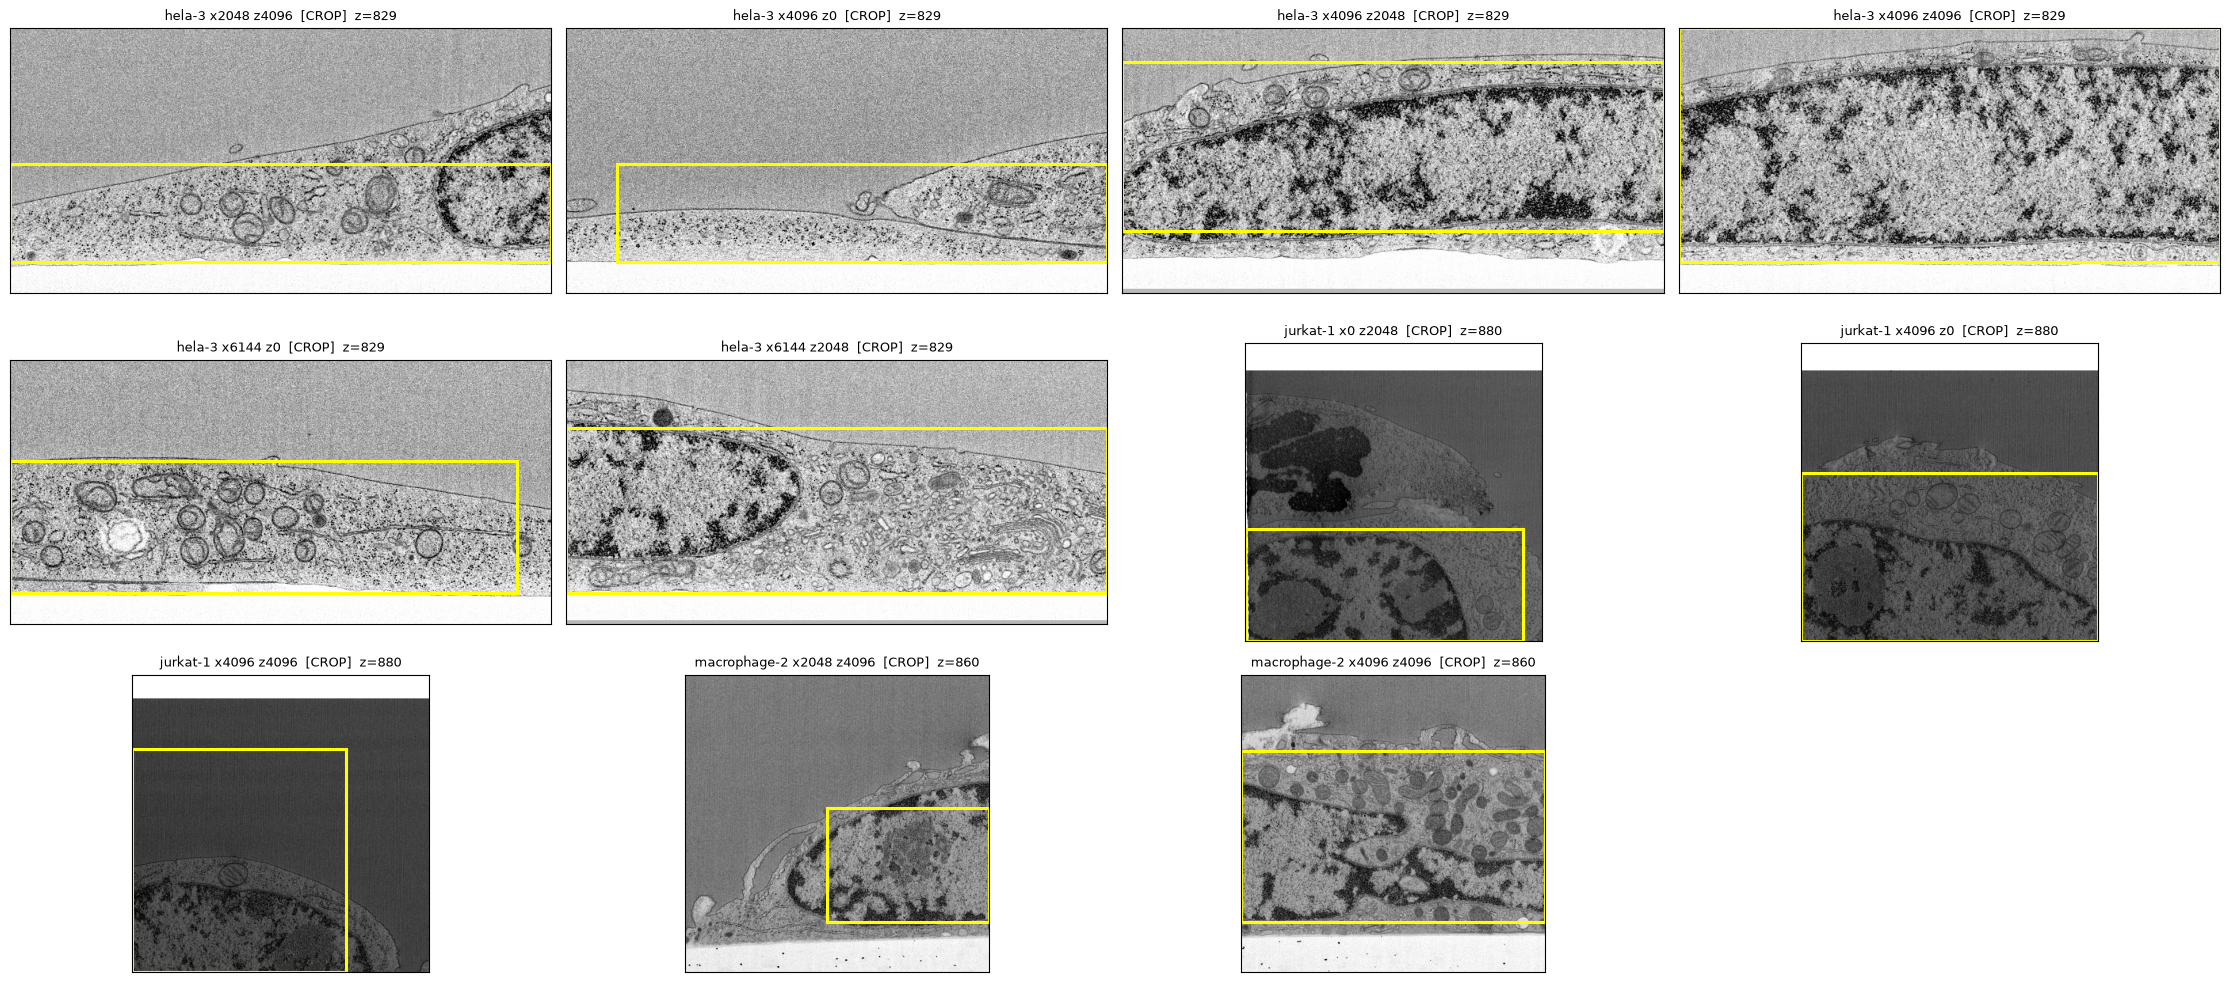

In [14]:
# overview: mid-z slice of every tile with its meaningful box (solid = box contains this z, dashed = box is at other z)
n = len(TILES); cols = 4; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5.6 * cols, 3.3 * rows)); axes = np.atleast_1d(axes).ravel()
COL = {"KEEP": "lime", "CROP": "yellow", "DROP": "red"}
for ax, t in zip(axes, TILES):
    d = vol(t["file"]); zmid = d.shape[0] // 2
    h = t["scan"]["hist"].astype(float); cdf = np.cumsum(h) / h.sum()
    lo, hi = int(np.searchsorted(cdf, 0.005)), int(np.searchsorted(cdf, 0.995))
    ax.imshow(d[zmid, ::3, ::3], cmap="gray", vmin=lo, vmax=max(hi, lo + 1), extent=(0, d.shape[2], d.shape[1], 0))
    b = t["box"]
    if b is not None:
        z0, z1, y0, y1, x0, x1 = b["box"]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=COL[t["verdict"]], lw=2.2, ls="-" if z0 <= zmid < z1 else "--"))
    ax.set_title(f"{t['ds'].replace('jrc_','')} x{t['x0']} z{t['z0']}  [{t['verdict']}]  z={zmid}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()


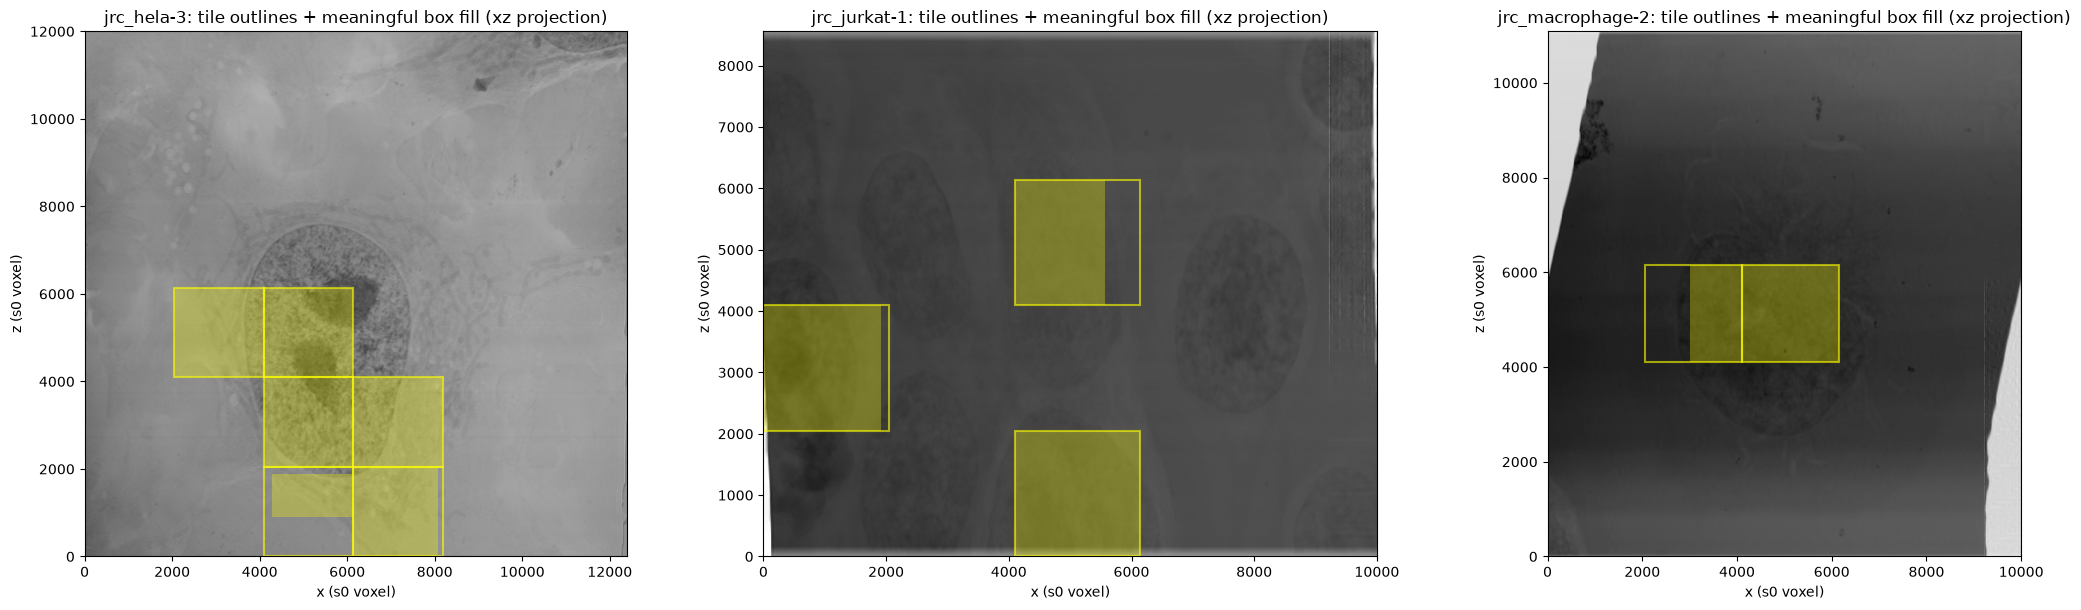

In [15]:
# boxes on the full-cell coarse maps (xz): meaningful region of each tile in source coordinates
fig, axes = plt.subplots(1, len(DS_ORDER), figsize=(7.2 * len(DS_ORDER), 6.2)); axes = np.atleast_1d(axes)
for ax, ds in zip(axes, DS_ORDER):
    a = get_mip(ds); X, Y, Z = ONL[ds]["size"]
    if a is not None:
        vlo, vhi = np.percentile(a, [1, 99.5])
        ax.imshow(a.mean(1), cmap="gray", origin="lower", extent=(0, a.shape[2] * F, 0, a.shape[0] * F), vmin=vlo, vmax=vhi)
    for t in [t for t in TILES if t["ds"] == ds]:
        ax.add_patch(Rectangle((t["x0"], t["z0"]), BOX, BOX, fill=False, ec=COL[t["verdict"]], lw=1.5, alpha=0.6))
        if t["box"] is not None:
            z0, z1, y0, y1, x0, x1 = t["box"]["box"]; k = BOX / t["shape"][0]            # 4 nm z index -> source z voxels
            ax.add_patch(Rectangle((t["x0"] + x0, t["z0"] + z0 * k), x1 - x0, (z1 - z0) * k, fc=COL[t["verdict"]], alpha=0.30, ec="none"))
    ax.set_xlim(0, X); ax.set_ylim(0, Z); ax.set_title(f"{ds}: tile outlines + meaningful box fill (xz projection)"); ax.set_xlabel("x (s0 voxel)"); ax.set_ylabel("z (s0 voxel)")
plt.tight_layout(); plt.show()


## 9. Sensitivity: how robust is the verdict to the gates?

The verdict should not hinge on one threshold. Same boxes, but re-run with (a) `MIN_AC` 0.4 / 0.6, (b) plain 0-255 scaling for `content_frac` / `autocorr` instead of the sidecar.


In [16]:
def meaningful_fraction(t, ac_thr=MIN_AC, full_scale=False):
    M = t["scan"]["M"]
    cf = M[..., 2 if full_scale else 0]; ac = M[..., 3 if full_scale else 1]
    ok = (cf >= MIN_CONTENT) & (ac >= ac_thr) & (M[..., 4] >= MIN_NZ)
    return float(ok.mean())


print(f"{'tile':44s} {'verdict':7s} {'ac>=0.4':>8s} {'ac>=0.5':>8s} {'ac>=0.6':>8s} {'0-255 scaling':>14s}  (fraction of meaningful patches)")
for t in TILES:
    print(f"{t['name']:44s} {t['verdict']:7s} {meaningful_fraction(t, 0.4):8.2f} {meaningful_fraction(t):8.2f} {meaningful_fraction(t, 0.6):8.2f} {meaningful_fraction(t, full_scale=True):14.2f}")
    d_ = abs(meaningful_fraction(t, full_scale=True) - meaningful_fraction(t))
    check(f"verdict not an artefact of the sidecar scaling [{t['name']}]", d_ < 0.15, f"meaningful fraction differs by {d_:.2f} between sidecar and 0-255 scaling", warn=True)


tile                                         verdict  ac>=0.4  ac>=0.5  ac>=0.6  0-255 scaling  (fraction of meaningful patches)
jrc_hela-3_4nm_x2048_y0_z4096                CROP        0.47     0.44     0.41           0.44
[PASS] verdict not an artefact of the sidecar scaling [jrc_hela-3_4nm_x2048_y0_z4096]  --  meaningful fraction differs by 0.00 between sidecar and 0-255 scaling
jrc_hela-3_4nm_x4096_y0_z0                   CROP        0.40     0.39     0.36           0.39
[PASS] verdict not an artefact of the sidecar scaling [jrc_hela-3_4nm_x4096_y0_z0]  --  meaningful fraction differs by 0.00 between sidecar and 0-255 scaling
jrc_hela-3_4nm_x4096_y0_z2048                CROP        0.71     0.71     0.67           0.71
[PASS] verdict not an artefact of the sidecar scaling [jrc_hela-3_4nm_x4096_y0_z2048]  --  meaningful fraction differs by 0.00 between sidecar and 0-255 scaling
jrc_hela-3_4nm_x4096_y0_z4096                CROP        0.83     0.81     0.79           0.81
[PASS] verd

## 10. Result: tiles and regions to keep (candidate rows for `docs/DATASETS.md`)

Only `KEEP` / `CROP` tiles are listed; `Size crop` is the meaningful box (x x y x z, 4 nm voxels) and `Subvolume size` the whole tile.
`Task`/`Split` are not decided here: the former config used the HeLa / macrophage / Jurkat tiles as SSL train and validation tiles.


In [17]:
def dtext(t):
    return {"jrc_hela-3": "HeLa cell (jrc_hela-3)", "jrc_jurkat-1": "Jurkat T cell (jrc_jurkat-1)", "jrc_macrophage-2": "THP-1 macrophage (jrc_macrophage-2)"}[t["ds"]]


rows_out = []
print("| Dataset | Modality | Region | Name | Num crops | Subvolume size (x x y x z) | Size crop (x x y x z) | Voxel size (nm) | Voxel count | verdict | z0:z1, y0:y1, x0:x1 |")
print("| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |")
tot = 0
for t in TILES:
    Z, Y, X = t["shape"]; b = t["box"]
    if t["verdict"] == "DROP":
        continue
    z0, z1, y0, y1, x0, x1 = b["box"]; vox = (x1 - x0) * (y1 - y0) * (z1 - z0); tot += vox
    nm = f"{t['ds'].replace('jrc_','')} x{t['x0']} z{t['z0']}"
    print(f"| COSEM3D | FIB-SEM | {dtext(t)} | {nm} | 1 | {X} x {Y} x {Z} | {x1-x0} x {y1-y0} x {z1-z0} | 4 x 4 x 4 | {vox:,} | {t['verdict']} | {z0}:{z1}, {y0}:{y1}, {x0}:{x1} |")
    rows_out.append((nm, t["verdict"], b["box"], vox))
print()
print("dropped tiles:", ", ".join(t["name"].split("_4nm_")[1].replace("_volume", "") + f" ({t['ds'].replace('jrc_','')})" for t in TILES if t["verdict"] == "DROP") or "none")
print(f"kept: {len(rows_out)} of {len(TILES)} tiles, {tot/1e9:.2f} G meaningful voxels of {sum(np.prod(t['shape']) for t in TILES)/1e9:.2f} G")
for t in TILES:
    check(f"tile is wholly meaningful [{t['name']}]", t["verdict"] == "KEEP",
          f"{t['verdict']}: box covers {t['box']['frac']:.0%} of the tile" if t["box"] else "DROP: no box passes", warn=t["verdict"] != "DROP")


| Dataset | Modality | Region | Name | Num crops | Subvolume size (x x y x z) | Size crop (x x y x z) | Voxel size (nm) | Voxel count | verdict | z0:z1, y0:y1, x0:x1 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| COSEM3D | FIB-SEM | HeLa cell (jrc_hela-3) | hela-3 x2048 z4096 | 1 | 2048 x 1000 x 1659 | 2048 x 372 x 1659 | 4 x 4 x 4 | 1,263,919,104 | CROP | 0:1659, 512:884, 0:2048 |
| COSEM3D | FIB-SEM | HeLa cell (jrc_hela-3) | hela-3 x4096 z0 | 1 | 2048 x 1000 x 1659 | 1856 x 372 x 800 | 4 x 4 x 4 | 552,345,600 | CROP | 724:1524, 512:884, 192:2048 |
| COSEM3D | FIB-SEM | HeLa cell (jrc_hela-3) | hela-3 x4096 z2048 | 1 | 2048 x 1000 x 1659 | 2048 x 640 x 1659 | 4 x 4 x 4 | 2,174,484,480 | CROP | 0:1659, 128:768, 0:2048 |
| COSEM3D | FIB-SEM | HeLa cell (jrc_hela-3) | hela-3 x4096 z4096 | 1 | 2048 x 1000 x 1659 | 2048 x 884 x 1659 | 4 x 4 x 4 | 3,003,506,688 | CROP | 0:1659, 0:884, 0:2048 |
| COSEM3D | FIB-SEM | HeLa cell (jrc_hela-3) | hela-3 x6144 z0 | 1 | 204

## 11. Everything that is not `PASS`

In [18]:
order = {"FAIL": 0, "WARN": 1, "INFO": 2, "PASS": 3}
cnt = {k: sum(r[0] == k for r in RESULTS) for k in order}
print("totals:", cnt, "\n")
for status, name, detail in sorted(RESULTS, key=lambda r: order[r[0]]):
    if status != "PASS":
        print(f"[{status}] {name}" + (f"  --  {detail}" if detail else ""))


totals: {'FAIL': 0, 'WARN': 34, 'INFO': 1, 'PASS': 177} 

[WARN] norm.json is the documented 0..255 [jrc_jurkat-1_4nm_x0_y0_z2048]  --  actual 205..237
[WARN] norm.json covers >= 97 % of voxels [jrc_jurkat-1_4nm_x0_y0_z2048]  --  9.4 % outside; 9.4 % above max
[WARN] saturation at 255 < 5 % [jrc_jurkat-1_4nm_x0_y0_z2048]  --  9.3 % of voxels == 255
[WARN] norm.json is the documented 0..255 [jrc_jurkat-1_4nm_x4096_y0_z0]  --  actual 208..238
[WARN] norm.json covers >= 97 % of voxels [jrc_jurkat-1_4nm_x4096_y0_z0]  --  9.6 % outside; 9.6 % above max
[WARN] saturation at 255 < 5 % [jrc_jurkat-1_4nm_x4096_y0_z0]  --  9.5 % of voxels == 255
[WARN] norm.json is the documented 0..255 [jrc_jurkat-1_4nm_x4096_y0_z4096]  --  actual 215..238
[WARN] norm.json covers >= 97 % of voxels [jrc_jurkat-1_4nm_x4096_y0_z4096]  --  7.9 % outside; 7.9 % above max
[WARN] saturation at 255 < 5 % [jrc_jurkat-1_4nm_x4096_y0_z4096]  --  7.8 % of voxels == 255
[WARN] norm.json is the documented 0..255 [jrc_macroph